# 04 · Item-based collaborative filtering (item-kNN)

**Learning objectives**

1. Compute item–item **cosine similarity** from co-occurrence, by hand and at scale.
2. Understand the knobs: neighbourhood size, **shrinkage** and **BM25** weighting.
3. Tune hyperparameters on a **validation** split, never on the test set.
4. Produce **explanations** ("because you viewed X").

Item-kNN is decades old ("customers who bought this also bought...", Amazon 2003) and still a top performer on session-heavy e-commerce data. It is cheap, it updates easily, and it explains itself.

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().resolve().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from recsys.data import load_or_synthesize
from recsys.pipeline import prepare_data
from recsys.metrics import evaluate, evaluate_many
from recsys.models import ItemKNNRecommender, PopularityRecommender
from recsys.plotting import set_style, PALETTE, model_color

set_style()
events, item_categories, SOURCE = load_or_synthesize()
data = prepare_data(events)

  USING SYNTHETIC DATA: data/raw/events.csv was not found.
  The numbers below come from a simulator, NOT from RetailRocket.
  Run `make data` (needs a Kaggle API token) to use the real dataset.


## 1. The idea on a toy matrix

Four users, three items. Represent each **item as a column vector** over users. Two items are similar if their columns point the same way:

$$ s(i, j) = \cos(\mathbf{r}_i, \mathbf{r}_j) = \frac{\mathbf{r}_i \cdot \mathbf{r}_j}{\|\mathbf{r}_i\|\,\|\mathbf{r}_j\|} $$

In [2]:
toy = pd.DataFrame([[1, 1, 0], [1, 1, 0], [0, 1, 1], [1, 0, 0]],
                   index=["ana", "ben", "cho", "dev"], columns=["tent", "stove", "kayak"])
R = toy.to_numpy(float)
norms = np.linalg.norm(R, axis=0)
S = (R.T @ R) / np.outer(norms, norms)
np.fill_diagonal(S, 0)
display(toy)
pd.DataFrame(S, index=toy.columns, columns=toy.columns).round(2)

,tent,stove,kayak
ana,1,1,0
ben,1,1,0
cho,0,1,1
dev,1,0,0


,tent,stove,kayak
tent,0.00,0.67,0.00
stove,0.67,0.00,0.58
kayak,0.00,0.58,0.00


Scoring a user means summing the similarities from the items they have interacted with:

$$ \text{score}(u, i) = \sum_{j \in \mathcal{H}(u)} r_{uj}\, s(j, i) $$

`dev` only has the tent, so `score(dev, stove) = 0.67` and `score(dev, kayak) = 0`. We recommend the stove. In matrix form this is just `R @ S`, which is what `ItemKNNRecommender.score` does on a sparse matrix.

In [3]:
pd.DataFrame(R @ S, index=toy.index, columns=toy.columns).round(2)

,tent,stove,kayak
ana,0.67,0.67,0.58
ben,0.67,0.67,0.58
cho,0.67,0.58,0.58
dev,0.00,0.67,0.00


## 2. Three practical refinements

| Knob | Problem it solves |
|---|---|
| **Top-K neighbours** | Thousands of tiny, noisy similarities add up to nonsense. Keep each item's K strongest. This also keeps the matrix sparse. |
| **Shrinkage** `λ` | Two items co-viewed by *one* user can have cosine 1.0. With `dot / (‖i‖‖j‖ + λ)`, evidence from few users is shrunk towards 0. |
| **BM25 weighting** | Heavy users co-occur with everything, and repeated interactions saturate. BM25 (from search engines) down-weights both. |

## 3. Tune on validation, not on test

> **Principal DS note.** If you pick hyperparameters by looking at test-set scores, the test set is no longer an unbiased estimate. You have *fitted* to it. We carve a **validation** split out of the training period: same protocol, shifted one week earlier.

```
 ───────── val-train ─────────┃── val ──┃── test ──▶
 ──────────────── train ────────────────┃
```

In [4]:
val = prepare_data(events[events["timestamp"] < data.cutoff])
print(f"validation: {val.X_train.shape[0]:,} users × {val.X_train.shape[1]:,} items, {len(val.ground_truth):,} eval users")

validation: 2,364 users × 966 items, 639 eval users


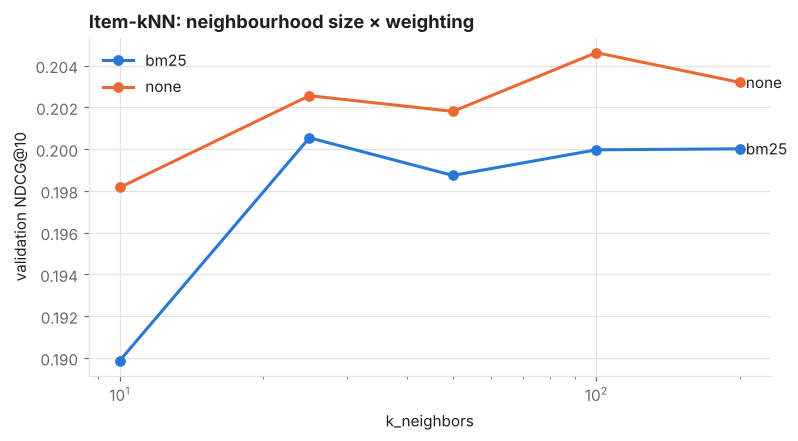

In [5]:
results = []
for weighting in ["none", "bm25"]:
    for k in [10, 25, 50, 100, 200]:
        m = ItemKNNRecommender(k_neighbors=k, shrinkage=10, weighting=weighting).fit(val.X_train)
        results.append({"weighting": weighting, "k_neighbors": k, **evaluate(m, val.X_train, val.ground_truth)})
sweep = pd.DataFrame(results)

fig, ax = plt.subplots()
for c, (w, grp) in zip(PALETTE, sweep.groupby("weighting")):
    ax.plot(grp["k_neighbors"], grp["ndcg@10"], marker="o", color=c, label=w)
    ax.annotate(w, (grp["k_neighbors"].iloc[-1], grp["ndcg@10"].iloc[-1]), xytext=(4, 0), textcoords="offset points", va="center")
ax.set_xscale("log"); ax.set_xlabel("k_neighbors"); ax.set_ylabel("validation NDCG@10")
ax.set_title("Item-kNN: neighbourhood size × weighting"); ax.legend()
plt.show()

In [6]:
shrink = []
best_w, best_k = sweep.loc[sweep["ndcg@10"].idxmax(), ["weighting", "k_neighbors"]]
for s in [0, 1, 10, 50, 200]:
    m = ItemKNNRecommender(k_neighbors=int(best_k), shrinkage=s, weighting=best_w).fit(val.X_train)
    shrink.append({"shrinkage": s, "ndcg@10": evaluate(m, val.X_train, val.ground_truth)["ndcg@10"]})
shrink = pd.DataFrame(shrink).set_index("shrinkage")
best_s = shrink["ndcg@10"].idxmax()
print(f"best on validation: weighting={best_w}, k_neighbors={best_k}, shrinkage={best_s}")
shrink.round(4)

best on validation: weighting=none, k_neighbors=100, shrinkage=200


,ndcg@10
shrinkage,
0,0.1929
1,0.1960
10,0.2046
50,0.2035
200,0.2076


## 4. Final evaluation on the test period

Refit with the chosen hyperparameters on the **full** training period, then evaluate **once** on test.

In [7]:
knn = ItemKNNRecommender(k_neighbors=int(best_k), shrinkage=best_s, weighting=best_w).fit(data.X_train)
board = evaluate_many({"item_knn": knn, "popularity": PopularityRecommender().fit(data.X_train)},
                      data.X_train, data.ground_truth)
board.round(4)

,precision@10,recall@10,hit_rate@10,map@10,ndcg@10,mrr,coverage,novelty,n_users
item_knn,0.0652,0.2515,0.4769,0.1325,0.1941,0.2533,0.2112,4.8724,627
popularity,0.0293,0.1037,0.2568,0.0340,0.0664,0.0927,0.0194,3.2515,627


## 5. Similar items, and a sanity check with categories

A quick qualitative check: are an item's neighbours in the same category? Item-kNN never sees categories, so agreement here means the co-occurrence signal is meaningful.

In [8]:
cat_of = dict(zip(item_categories["itemid"], item_categories["categoryid"])) if item_categories is not None else {}
popular_items = np.argsort(-np.asarray((data.X_train > 0).sum(axis=0)).ravel())[:3]
for item in popular_items:
    nbrs, sims = knn.similar_items(item, n=5)
    raw = data.item_map.to_raw(item)
    print(f"item {raw} (category {cat_of.get(raw, '?')}) → neighbours:")
    for r, s in zip(data.item_map.to_raw(nbrs), sims):
        print(f"     {r:>8}  sim={s:.3f}  category={cat_of.get(r, '?')}")

item 4477 (category 3) → neighbours:
         6772  sim=0.388  category=3
         3315  sim=0.214  category=3
        12090  sim=0.214  category=3
        11424  sim=0.202  category=3
        10740  sim=0.199  category=3
item 5446 (category 8) → neighbours:
         3474  sim=0.426  category=8
         9258  sim=0.312  category=8
          502  sim=0.271  category=8
         2104  sim=0.213  category=8
        10769  sim=0.200  category=8
item 2599 (category 4) → neighbours:
         8201  sim=0.420  category=4
         2533  sim=0.304  category=4
         6317  sim=0.298  category=4
         6696  sim=0.199  category=4
        10309  sim=0.155  category=4


In [9]:
if cat_of:
    agree = []
    for item in range(0, data.X_train.shape[1], max(1, data.X_train.shape[1] // 2000)):
        nbrs, _ = knn.similar_items(item, n=5)
        c = cat_of.get(data.item_map.to_raw(item))
        if len(nbrs) and c is not None:
            agree.append(np.mean([cat_of.get(r) == c for r in data.item_map.to_raw(nbrs)]))
    print(f"share of top-5 neighbours in the same category: {np.mean(agree):.1%}")

share of top-5 neighbours in the same category: 77.5%


## 6. Explaining a recommendation

Every score is a sum of contributions from items in the user's history, so the explanation comes for free:

In [10]:
user = int(data.ground_truth.users[0])
for item in knn.recommend([user], k=3)[0]:
    because = knn.explain(user, int(item))
    reasons = ", ".join(f"{data.item_map.to_raw(j)} ({w:.2f})" for j, w in because)
    print(f"recommend {data.item_map.to_raw(item)}  ← because you interacted with {reasons}")

recommend 8885  ← because you interacted with 4650 (0.73), 5592 (0.59), 6618 (0.36)
recommend 5446  ← because you interacted with 7427 (0.52), 4650 (0.23), 5592 (0.14)
recommend 2599  ← because you interacted with 7427 (0.51), 4650 (0.21), 4477 (0.18)


Merchandisers trust what they can understand. That matters for adoption as much as NDCG does.

## Key takeaways

* Item-kNN = sparse matrix multiplication with a pruned similarity matrix.
* Shrinkage, top-K pruning and BM25 matter as much as the choice of algorithm.
* **Tune on validation, report on test, once.**
* Explainability is a feature, not a nice-to-have.

## Exercises

1. **(Easy)** Implement *asymmetric cosine*, $s(i,j)= \frac{r_i\cdot r_j}{\|r_i\|^{2\alpha}\|r_j\|^{2(1-\alpha)}}$, and sweep α.
2. **(Medium)** Build a *session co-visitation* model: items are similar if viewed in the **same session** (30-minute gap rule), not merely by the same user. Does it beat user-level co-occurrence?
3. **(Medium)** Implement **user-kNN** by symmetry. How do its speed and accuracy compare?
4. **(Stretch)** Implement **EASE** (Steck, 2019): $B = I - P\,\mathrm{diagMat}(1/\mathrm{diag}(P))$ with $P=(X^\top X+\lambda I)^{-1}$. Restrict it to the top 10k items. It is one of the strongest simple baselines in the literature.